In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

In [2]:
base = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

In [3]:
base.trainable = False

In [4]:
model = models.Sequential([
    layers.Input(shape=(96, 96, 3)),

    layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),

    base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])

In [5]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

In [6]:
x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 78s 47ms/step - accuracy: 0.8016 - loss: 0.5904 - val_accuracy: 0.8445 - val_loss: 0.4374
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 49ms/step - accuracy: 0.8512 - loss: 0.4385 - val_accuracy: 0.8536 - val_loss: 0.4163
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 77s 49ms/step - accuracy: 0.8678 - loss: 0.3893 - val_accuracy: 0.8607 - val_loss: 0.3989


In [9]:
#finetune
base.trainable = True

for layer in base.layers[:-20]:
    layer.trainable = False

for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [10]:
#compile again
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
#train again
history_fine = model.fit(
    x_train, y_train,
    epochs=2,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 89s 54ms/step - accuracy: 0.8597 - loss: 0.4185 - val_accuracy: 0.8849 - val_loss: 0.3448
Epoch 2/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 85s 55ms/step - accuracy: 0.8964 - loss: 0.3047 - val_accuracy: 0.8820 - val_loss: 0.3599


In [15]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 43ms/step - accuracy: 0.8820 - loss: 0.3599
Test Accuracy: 0.8820000290870667


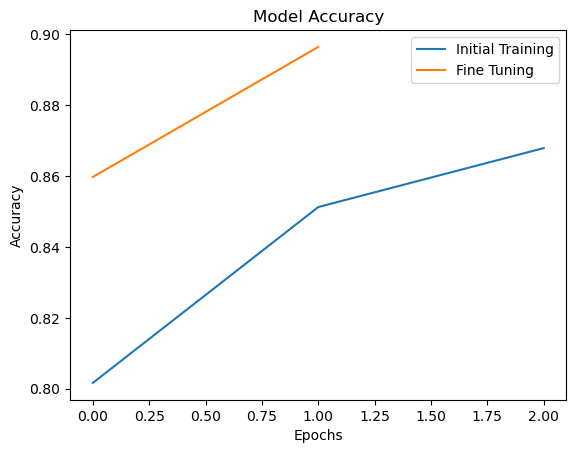

In [16]:
plt.plot(history.history['accuracy'])
plt.plot(history_fine.history['accuracy'])

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(["Initial Training", "Fine Tuning"])
plt.show()